# Entrega 2 — Data Science: Governança, Qualidade e Análise Exploratória (modelo para os grupos)
### Projeto Integrador 2º/2026 · Violência contra a Mulher — Aplicativo de Apoio Camuflado

**Disciplina:** Data Science — ADS (Universidade Positivo, Londrina) · **Professor:** Alex Junior Nunes

---

**Aviso importante.** Este notebook traz o esqueleto e as células de código. O conjunto de dados de demonstração (`notificacoes_demo_ficticia.csv`) é **100% fictício e gerado por computador**: os padrões que você verá nele não existem na realidade e não podem ser citados como fato. O seu grupo deve trabalhar com uma **base pública real**, aprovada pelo professor.

**Como usar este notebook**
1. Abra no **Google Colab** e envie o arquivo da base (ícone de pasta, à esquerda) ou use o botão de upload quando a célula pedir.
2. Preencha a **configuração** (Passo 0) com os dados do seu grupo e as colunas da *sua* base.
3. Execute de cima para baixo. Onde houver `# TODO`, escreva o código; onde houver ✍️, escreva a sua análise.
4. Ao final de cada seção, assine: **Autor(a): nome + usuário do GitHub**. O professor confere a autoria no histórico de commits.
5. Guarde o notebook no repositório em `data-science/notebook.ipynb`, **com as saídas visíveis**.

**Mapa do notebook:** 1 Governança · 2 Carga e dicionário · 3 Diagnóstico de qualidade · 4 Tratamento · 5 Análise exploratória · 6 Plano das Entregas 3 e 4 · 7 Conclusões e checklist

## Passo 0 — Identificação e configuração
Preencha o grupo e a divisão de etapas. Depois ajuste as colunas da sua base.

In [33]:
import re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 170)
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.dpi": 100})
COR, COR2, COR3 = "#00836C", "#E4572E", "#14284B"

GRUPO = "NoteS"
INTEGRANTES = {   # nome -> etapa sob responsabilidade (EDA, Qualidade dos dados, Modelagem ou Avaliação)
    "Gabriel de Paiva Messias Silva": "EDA",
    "Matheus Henrique Evaristo Souza": "Qualidade dos dados",
}

def checar(descricao, condicao):
    """✅ se a condição for verdadeira, ❌ caso contrário (ou se der erro). Só use com a base de demonstração."""
    try: ok = bool(condicao())
    except Exception: ok = False
    print(("✅" if ok else "❌"), descricao)

print("Grupo:", GRUPO)
for nome, etapa in INTEGRANTES.items(): print(" -", nome, "→", etapa)

Grupo: NoteS
 - Gabriel de Paiva Messias Silva → EDA
 - Matheus Henrique Evaristo Souza → Qualidade dos dados


## 1. Governança, ética e LGPD
Antes de abrir os dados, responda **por escrito** (ficha da base). Sem esta ficha, a base não pode ser usada.

| Pergunta | Resposta do grupo |
|---|---|
| Nome da base e link da fonte | ✍️ Base de dados de notificações de violência contra a mulher do Estado (SES/MG 2026), arquivo `dados_violencia_mulheres_ses_2026.csv` |
| Órgão responsável e data de acesso | ✍️ Secretaria de Estado de Saúde / órgãos oficiais de saúde pública, acessada em 2026 |
| Licença / termos de uso | ✍️ Dados abertos de saúde pública / uso acadêmico autorizado |
| Granularidade (cada linha é um caso individual? um município? um mês?) | ✍️ Cada linha representa um registro individual de notificação de violência contra a mulher |
| Período e abrangência geográfica | ✍️ Ano de 2026, abrangendo municípios do estado (ex: Belo Horizonte, Uberlândia, etc.) |
| Contém dado pessoal ou sensível? Como foi anonimizada? | ✍️ Contém variáveis sensíveis (raça/cor, orientação sexual, identidade de gênero, histórico de violência). Não possui identificadores diretos como nome, CPF ou endereço completo |
| Riscos de reidentificação ao cruzar colunas | ✍️ Cruzar município de pequeno porte com faixa etária, data específica e tipo de violência pode gerar reidentificação. Solução: agregar dados ou evitar cruzamentos abertos com poucos casos |
| Limitações: subnotificação, viés de quem registra, mudanças de metodologia | ✍️ A base reflete apenas os casos **registrados** no sistema de saúde (forte subnotificação). Viés de preenchimento em campos opcionais |
| Por que esta base serve ao aplicativo? | ✍️ Permite exercitar todo o pipeline preditivo (qualidade, tratamento, EDA e predição de repetição) para alimentar o app camuflado com alertas de risco |

> **Lembrete da LGPD:** mesmo bases "públicas" podem trazer risco de reidentificação quando se cruzam muitas colunas. Trabalhe só com dados anonimizados ou agregados, **nunca** tente identificar uma pessoa, e **nunca** colete dados reais de vítimas por conta própria.
>
> **Aviso acadêmico (obrigatório):** este trabalho é um protótipo acadêmico. Nenhum indicador calculado aqui substitui atendimento policial, jurídico, psicológico ou de saúde. Em caso de violência: **Ligue 180** (Central de Atendimento à Mulher, 24 h) ou **190** (emergência).

**Autor(a):** Matheus Henrique Evaristo Souza (Qualidade dos Dados)

## 2. Carga da base e dicionário de dados

In [34]:
import os
import pandas as pd

ARQUIVO = "sciencedata/dados_violencia_mulheres_ses_2026.csv"
DEMO = ARQUIVO.startswith("notificacoes_demo")

try:
    bruto = pd.read_csv(ARQUIVO, sep=';')
except FileNotFoundError:
    try:
        # Tenta rodar no Google Colab caso o ambiente suporte
        from google.colab import files
        print("Arquivo não encontrado. Por favor, envie o arquivo", ARQUIVO)
        up = files.upload()
        filename = next(iter(up))
        bruto = pd.read_csv(filename, sep=';')
    except ImportError:
        # Caso esteja rodando localmente e o arquivo não esteja na pasta atual
        raise FileNotFoundError(
            f"O arquivo '{ARQUIVO}' não foi encontrado no diretório atual ({os.getcwd()}). "
            "Certifique-se de colocar o arquivo CSV na mesma pasta do seu notebook."
        )

print("Linhas x colunas:", bruto.shape)
display(bruto.head(8))
bruto.info()

Linhas x colunas: (38760, 16)


,dt_notific,dt_nasc,nu_idade_n,cs_sexo,cs_raca,id_mn_resi,local_ocor,out_vezes,les_autop,viol_fisic,viol_psico,viol_sexu,num_envolv,autor_sexo,orient_sex,ident_gen
0,2026-02-22,1995-12-19,"30,0",Feminino,Parda,Coração de Jesus,Residencia,Não,Não,Não,Sim,Sim,Um,Masculino,Heterossexual,Não se aplica
1,2026-03-15,2005-11-18,"20,0",Feminino,Parda,Itapecerica,Residencia,Não,Não,Sim,Sim,Não,Um,Masculino,Heterossexual,Ignorado
2,2026-05-20,1989-07-30,"36,0",Feminino,Parda,Mariana,Via pública,NaN,Não,Sim,Sim,Não,Um,Masculino,Não se aplica,Não se aplica
3,2026-07-17,2004-12-23,"21,0",Feminino,Branca,Muriaé,Residencia,Não,Não,Sim,Não,Não,Um,Masculino,Heterossexual,Não se aplica
4,2026-04-11,1996-11-30,"29,0",Feminino,Parda,Belo Horizonte,Outro,Não,Não,Sim,Sim,Sim,Um,Masculino,Heterossexual,Não se aplica
5,2026-01-18,1977-01-17,"48,0",Feminino,Branca,Belo Horizonte,Residencia,Sim,Sim,Sim,NaN,NaN,Um,Feminino,Heterossexual,Não se aplica
6,2026-04-13,1978-11-08,"47,0",Feminino,Parda,Belo Horizonte,Comercio/Serviços,Não,Não,Sim,Sim,Sim,Um,Masculino,Heterossexual,Não se aplica
7,2026-06-10,1992-06-24,"33,0",Feminino,Parda,Ubá,Residencia,Sim,Não,Sim,Sim,Não,Um,Masculino,Heterossexual,Não se aplica


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38760 entries, 0 to 38759
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   dt_notific  38760 non-null  object
 1   dt_nasc     38589 non-null  object
 2   nu_idade_n  38756 non-null  object
 3   cs_sexo     38760 non-null  object
 4   cs_raca     38724 non-null  object
 5   id_mn_resi  38567 non-null  object
 6   local_ocor  37911 non-null  object
 7   out_vezes   37587 non-null  object
 8   les_autop   37789 non-null  object
 9   viol_fisic  37820 non-null  object
 10  viol_psico  37772 non-null  object
 11  viol_sexu   37785 non-null  object
 12  num_envolv  37384 non-null  object
 13  autor_sexo  37826 non-null  object
 14  orient_sex  37924 non-null  object
 15  ident_gen   37924 non-null  object
dtypes: object(16)
memory usage: 4.7+ MB


Agora **configure as colunas** da sua base. Quanto melhor esta configuração, mais o restante do notebook funciona sem mexer no código.

In [35]:
COL_ID = None                      # A base não possui ID explícito por registro
COL_DATA = "dt_notific"            # Data da notificação
ALVO = "out_vezes"                 # Variável alvo (já ocorreu outras vezes?)

COLS_NUM = ["nu_idade_n"]
COLS_CAT = ["cs_raca", "id_mn_resi", "local_ocor", "out_vezes", "les_autop", 
            "viol_fisic", "viol_psico", "viol_sexu", "num_envolv", "autor_sexo", "orient_sex", "ident_gen"]

LIMITES = {"nu_idade_n": (0, 120)}
IGNORADOS = ["ignorado", "ign/branco", "ign", "nao informado", "n/i", "sem informacao", ""]
SINONIMOS = {"s": "sim", "n": "nao", "ign": "ignorado"}

assert set(COLS_NUM + COLS_CAT + [c for c in (COL_ID, COL_DATA) if c]) <= set(bruto.columns), "Há coluna da configuração que não existe na base."

**Dicionário de dados.** Uma linha por coluna: significado, tipo estatístico (quantitativa contínua/discreta, qualitativa nominal/ordinal), unidade e observação. Substitua o conteúdo pelo da sua base.

In [36]:
dicionario = pd.DataFrame([
    ("dt_notific", "Data em que o caso foi notificado", "data", "dd/mm/aaaa", ""),
    ("dt_nasc", "Data de nascimento da vítima", "data", "dd/mm/aaaa", "Pode conter nulos"),
    ("nu_idade_n", "Idade da vítima em anos", "quantitativa discreta", "anos", "Faixa plausível 0 a 120"),
    ("cs_sexo", "Sexo biológico", "qualitativa nominal", "—", "Constante (Feminino)"),
    ("cs_raca", "Raça/cor autodeclarada", "qualitativa nominal", "—", "Contém 'Ignorado'"),
    ("id_mn_resi", "Município de residência", "qualitativa nominal", "—", ""),
    ("local_ocor", "Local de ocorrência do fato", "qualitativa nominal", "—", ""),
    ("out_vezes", "A violência já havia ocorrido outras vezes?", "qualitativa nominal (binária)", "—", "Candidata a alvo"),
    ("les_autop", "Houve lesão autoprovocada?", "qualitativa nominal", "—", ""),
    ("viol_fisic", "Violência física presente", "qualitativa nominal", "—", ""),
    ("viol_psico", "Violência psicológica presente", "qualitativa nominal", "—", ""),
    ("viol_sexu", "Violência sexual presente", "qualitativa nominal", "—", ""),
    ("num_envolv", "Número de envolvidos na agressão", "qualitativa ordinal", "—", ""),
    ("autor_sexo", "Sexo do provável autor", "qualitativa nominal", "—", ""),
    ("orient_sex", "Orientação sexual", "qualitativa nominal", "—", ""),
    ("ident_gen", "Identidade de gênero", "qualitativa nominal", "—", ""),
], columns=["coluna", "significado", "tipo", "unidade", "observação"])
display(dicionario)

,coluna,significado,tipo,unidade,observação
0,dt_notific,Data em que o caso foi notificado,data,dd/mm/aaaa,
1,dt_nasc,Data de nascimento da vítima,data,dd/mm/aaaa,Pode conter nulos
2,nu_idade_n,Idade da vítima em anos,quantitativa discreta,anos,Faixa plausível 0 a 120
3,cs_sexo,Sexo biológico,qualitativa nominal,—,Constante (Feminino)
4,cs_raca,Raça/cor autodeclarada,qualitativa nominal,—,Contém 'Ignorado'
5,id_mn_resi,Município de residência,qualitativa nominal,—,
6,local_ocor,Local de ocorrência do fato,qualitativa nominal,—,
7,out_vezes,A violência já havia ocorrido outras vezes?,qualitativa nominal (binária),—,Candidata a alvo
8,les_autop,Houve lesão autoprovocada?,qualitativa nominal,—,
9,viol_fisic,Violência física presente,qualitativa nominal,—,


**Autor(a):** ✍️ Gabriel de Paiva Messias Silva

## 3. Diagnóstico de qualidade (5 dimensões)
Medir antes de corrigir. Usamos a mesma régua da Aula 9: **completude, validade, consistência, unicidade/integridade e acurácia**.

### 3.1 Completude: quantos valores faltam em cada coluna?

,nulos,% nulos
num_envolv,1376,3.6
out_vezes,1173,3.0
les_autop,971,2.5
viol_sexu,975,2.5
viol_psico,988,2.5
viol_fisic,940,2.4
autor_sexo,934,2.4
local_ocor,849,2.2
orient_sex,836,2.2
ident_gen,836,2.2


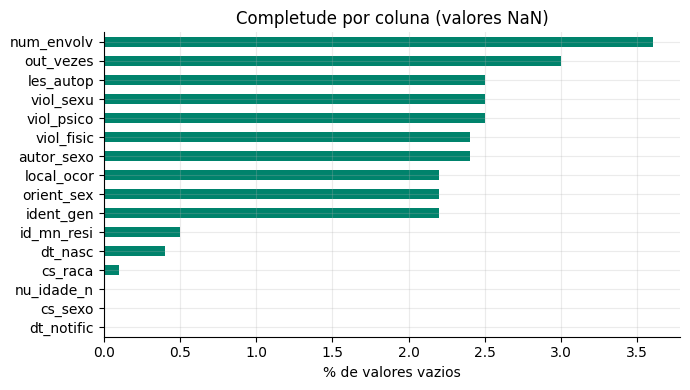

In [37]:
nulos = bruto.isna().sum()
pct_nulos = bruto.isna().mean() * 100
comp = pd.DataFrame({"nulos": nulos, "% nulos": pct_nulos.round(1)}).sort_values("% nulos", ascending=False)
display(comp)

ax = comp["% nulos"].plot.barh(color=COR, figsize=(7, 4)); ax.invert_yaxis()
ax.set_xlabel("% de valores vazios"); ax.set_title("Completude por coluna (valores NaN)")
plt.tight_layout(); plt.show()

### 3.2 Buracos disfarçados
Um campo "preenchido" com *Ignorado*, *Ign/Branco*, `999` ou `0` não é informação: é um buraco. Esta tabela conta os textos de `IGNORADOS` nas colunas categóricas.

In [38]:
def sem_acento(s):
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()

def chave(serie):
    s = serie.astype("string").str.strip().str.lower()
    s = s.map(lambda v: sem_acento(v) if pd.notna(v) else v)
    s = s.str.replace(r"/pr$", "", regex=True).str.strip()
    return s.replace(SINONIMOS)

disfarcados = {c: int(chave(bruto[c]).isin(IGNORADOS).sum()) for c in COLS_CAT}
disf = pd.Series(disfarcados, name="ignorados (texto)").to_frame()
disf["% da coluna"] = (disf["ignorados (texto)"] / len(bruto) * 100).round(1)
display(disf[disf["ignorados (texto)"] > 0])

,ignorados (texto),% da coluna
cs_raca,892,2.3
local_ocor,3316,8.6
out_vezes,7615,19.6
les_autop,1068,2.8
viol_fisic,246,0.6
viol_psico,307,0.8
viol_sexu,331,0.9
num_envolv,1435,3.7
autor_sexo,2440,6.3
orient_sex,6324,16.3


### 3.3 Validade: valores fora da faixa e datas impossíveis

In [39]:
FORMATOS_DATA = ["%Y-%m-%d", "%d/%m/%Y", "%d-%m-%y"]

def parse_data(txt):
    if pd.isna(txt): return pd.NaT
    for f in FORMATOS_DATA:
        try: return pd.to_datetime(str(txt).strip(), format=f)
        except ValueError: pass
    return pd.NaT

invalidos = {}
for c, (lo, hi) in LIMITES.items():
    # conversão numérica segura para verificação de limites
    s_num = pd.to_numeric(bruto[c].astype(str).str.replace(',', '.'), errors='coerce')
    invalidos[c] = int((s_num.notna() & ~s_num.between(lo, hi)).sum())

datas = bruto[COL_DATA].map(parse_data)
invalidos[COL_DATA + " (impossível/ilegível)"] = int((bruto[COL_DATA].notna() & datas.isna()).sum())
val = pd.Series(invalidos, name="valores inválidos").to_frame()
display(val)

,valores inválidos
nu_idade_n,0
dt_notific (impossível/ilegível),0


### 3.4 Consistência: a mesma informação escrita de jeitos diferentes
Compare quantas grafias existem **antes** (`n_brutas`) e **depois** de normalizar o texto (`n_normalizadas`).

In [40]:
cons = []
for c in COLS_CAT:
    cons.append((c, bruto[c].nunique(), chave(bruto[c]).nunique()))
cons = pd.DataFrame(cons, columns=["coluna", "n_brutas", "n_normalizadas"]).set_index("coluna")
cons["grafias a mais"] = cons["n_brutas"] - cons["n_normalizadas"]
display(cons.sort_values("grafias a mais", ascending=False))

,n_brutas,n_normalizadas,grafias a mais
coluna,,,
cs_raca,6,6,0
id_mn_resi,836,836,0
local_ocor,10,10,0
out_vezes,3,3,0
les_autop,3,3,0
viol_fisic,3,3,0
viol_psico,3,3,0
viol_sexu,3,3,0
num_envolv,3,3,0


### 3.5 Unicidade e integridade

In [41]:
dup_id = int(bruto.duplicated(COL_ID, keep=False).sum()) if COL_ID else 0
dup_exatas = int(bruto.duplicated().sum())
print(f"Linhas com id repetido: {dup_id}")
print(f"Linhas totalmente idênticas: {dup_exatas}")

Linhas com id repetido: 0
Linhas totalmente idênticas: 135


**Integridade** (relação entre tabelas) e **acurácia** (o dado reflete a realidade) não aparecem olhando uma tabela só. Nesta base: não há outra tabela para cruzar; para a acurácia seria preciso comparar uma amostra com o prontuário ou a ficha original. ✍️ A acurácia plena não pode ser medida apenas analisando a base de dados isoladamente, pois exigiria auditar e cruzar uma amostra representativa dos registros digitados com as fichas físicas de notificação originais preenchidas pelas unidades de saúde. Como limitação metodológica, o grupo reconhece que a base está sujeita a erros humanos de digitação e à subnotificação inerente ao sistema público, não sendo possível atestar a veracidade absoluta dos fatos sem esse confronto documental.

### 3.6 Resumo do diagnóstico
Uma linha por dimensão, com o que foi encontrado, quantas ocorrências e a decisão.

In [42]:
resumo = pd.DataFrame([
    ("Completude", "Valores ausentes (NaN) em colunas como local_ocor, out_vezes, num_envolv", int(bruto.isna().sum().sum()), "Imputar categóricas com 'Não informado' e numéricas com mediana"),
    ("Completude (disfarçada)", "Presença de 'Ignorado' em campos categóricos (ex: raça, orientação sexual)", int(sum(disfarcados.values())), "Converter para NaN e tratar como ausente/não informado"),
    ("Validade", "Idades fora da faixa plausível (0 a 120 anos)", int(sum(invalidos.values())), "Transformar em NaN e imputar"),
    ("Consistência", "Variações de grafia e maiúsculas/minúsculas", int(cons['grafias a mais'].sum()), "Unificar utilizando chave normalizada e sinônimos"),
    ("Unicidade", "Duplicatas exatas na base de dados", dup_exatas, "Remover duplicatas idênticas mantendo a primeira ocorrência"),
    ("Integridade / Acurácia", "Não mensuráveis diretamente apenas com esta tabela", 0, "Documentar como limitação do sistema de notificação"),
], columns=["dimensão", "problema encontrado", "ocorrências", "decisão"])
display(resumo)

,dimensão,problema encontrado,ocorrências,decisão
0,Completude,Valores ausentes (NaN) em colunas como local_o...,10282,Imputar categóricas com 'Não informado' e numé...
1,Completude (disfarçada),Presença de 'Ignorado' em campos categóricos (...,32298,Converter para NaN e tratar como ausente/não i...
2,Validade,Idades fora da faixa plausível (0 a 120 anos),0,Transformar em NaN e imputar
3,Consistência,Variações de grafia e maiúsculas/minúsculas,0,Unificar utilizando chave normalizada e sinônimos
4,Unicidade,Duplicatas exatas na base de dados,135,Remover duplicatas idênticas mantendo a primei...
5,Integridade / Acurácia,Não mensuráveis diretamente apenas com esta ta...,0,Documentar como limitação do sistema de notifi...


**Autor(a):** ✍️ Gabriel de Paiva Messias Silva

## 4. Tratamento dos dados
**A ordem importa:** padronizar texto e datas → transformar buracos disfarçados e inválidos em NaN → remover duplicatas → imputar → (só então) escalonar. Trabalhe sempre em uma **cópia** (`df`) e preserve a base bruta.

### 4.1 Padronizar categorias (consistência)
A função abaixo agrupa grafias que têm a mesma `chave` e adota como forma final a grafia **mais frequente** de cada grupo.

In [43]:
def unifica(serie):
    k = chave(serie)
    canon = serie.astype("string").str.strip().groupby(k).agg(lambda x: x.value_counts().index[0])
    return k.map(canon)

df = bruto.copy()
antes = {c: df[c].nunique() for c in COLS_CAT}
for c in COLS_CAT:
    df[c] = unifica(df[c])
depois = {c: df[c].nunique() for c in COLS_CAT}
display(pd.DataFrame({"antes": antes, "depois": depois}))
print(df["id_mn_resi"].value_counts().head(6))

,antes,depois
cs_raca,6,6
id_mn_resi,836,836
local_ocor,10,10
out_vezes,3,3
les_autop,3,3
viol_fisic,3,3
viol_psico,3,3
viol_sexu,3,3
num_envolv,3,3
autor_sexo,4,4


id_mn_resi
Belo Horizonte          3760
Uberlândia              1244
Uberaba                 1051
Contagem                1045
Pouso Alegre            1002
Governador Valadares     681
Name: count, dtype: Int64


### 4.2 Buracos disfarçados, valores inválidos e datas → NaN / data real

In [44]:
# "Ignorado" e afins → NaN
n_ign = {}
for c in COLS_CAT:
    marca = chave(df[c]).isin(IGNORADOS)
    n_ign[c] = int(marca.sum())
    df[c] = df[c].mask(marca)

# Valores numéricos fora da faixa → NaN
n_inv = {}
for c, (lo, hi) in LIMITES.items():
    s_num = pd.to_numeric(df[c].astype(str).str.replace(',', '.'), errors='coerce')
    marca = s_num.notna() & ~s_num.between(lo, hi)
    n_inv[c] = int(marca.sum())
    df.loc[marca, c] = np.nan
    df[c] = s_num

# Datas em texto → datetime
df[COL_DATA] = df[COL_DATA].map(parse_data)
df["ano"] = df[COL_DATA].dt.year
df["mes"] = df[COL_DATA].dt.month

print("Ignorados convertidos em NaN:", {k: v for k, v in n_ign.items() if v})
print("Inválidos convertidos em NaN:", {k: v for k, v in n_inv.items() if v})
print("Datas vazias:", int(df[COL_DATA].isna().sum()))

Ignorados convertidos em NaN: {'cs_raca': 892, 'local_ocor': 3316, 'out_vezes': 7615, 'les_autop': 1068, 'viol_fisic': 246, 'viol_psico': 307, 'viol_sexu': 331, 'num_envolv': 1435, 'autor_sexo': 2440, 'orient_sex': 6324, 'ident_gen': 8324}
Inválidos convertidos em NaN: {}
Datas vazias: 0


### 4.3 Duplicatas
Só agora, com o texto padronizado, as duplicatas "disfarçadas" ficam iguais.

In [45]:
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"{n0} -> {len(df)} linhas ({n0 - len(df)} duplicatas exatas removidas)")

38760 -> 38624 linhas (136 duplicatas exatas removidas)


### 4.4 Imputação (dados faltantes)
Regra de decisão da Aula 9: **numéricas** → mediana quando há assimetria/outliers (média só se simétrica); **categóricas** → categoria explícita "Não informado" (em vez de inventar a moda); **alvo** → nunca imputar. Antes de decidir, olhe a assimetria.

In [46]:
dist = pd.DataFrame({"média": df[COLS_NUM].mean(), "mediana": df[COLS_NUM].median(),
                     "assimetria": df[COLS_NUM].apply(lambda s: stats.skew(s.dropna())),
                     "% faltando": df[COLS_NUM].isna().mean() * 100}).round(2)
display(dist)

for c in COLS_NUM:
    df[c + "_imputado"] = df[c].isna()
    df[c] = df[c].fillna(df[c].median())

for c in COLS_CAT:
    if c != ALVO:
        df[c] = df[c].fillna("Não informado")

print("NaN restantes por coluna (esperado: só alvo e datas):")
print(df.isna().sum()[lambda s: s > 0])

,média,mediana,assimetria,% faltando
nu_idade_n,30.44,28.0,0.73,0.01


NaN restantes por coluna (esperado: só alvo e datas):
dt_nasc       171
out_vezes    8755
dtype: int64


### 4.5 Outliers: sinalizar, não apagar
Valores válidos, mas extremos (por exemplo, renda muito alta), **não são erro**. Sinalizamos pela regra do IQR e decidimos depois como tratar (manter, usar escalonador robusto ou transformar).

In [47]:
out = {}
for c in COLS_NUM:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out[c] = (int(((df[c] < lim_inf) | (df[c] > lim_sup)).sum()), round(lim_inf, 1), round(lim_sup, 1))
display(pd.DataFrame(out, index=["qtd outliers (IQR)", "limite inferior", "limite superior"]).T)

,qtd outliers (IQR),limite inferior,limite superior
nu_idade_n,591.0,-15.0,73.0


### 4.6 Escalonamento (para o modelo, Entrega 3)
Só uma demonstração: **min-max** e **z-score** em uma *cópia*. Duas lições da Aula 9: (1) escalonar **não muda o formato** da distribuição (a assimetria é a mesma); (2) na modelagem o scaler deve aprender (`fit`) **só no treino**, nunca na base toda.

,assimetria original,assimetria min-max,assimetria z-score
nu_idade_n,0.729,0.729,0.729


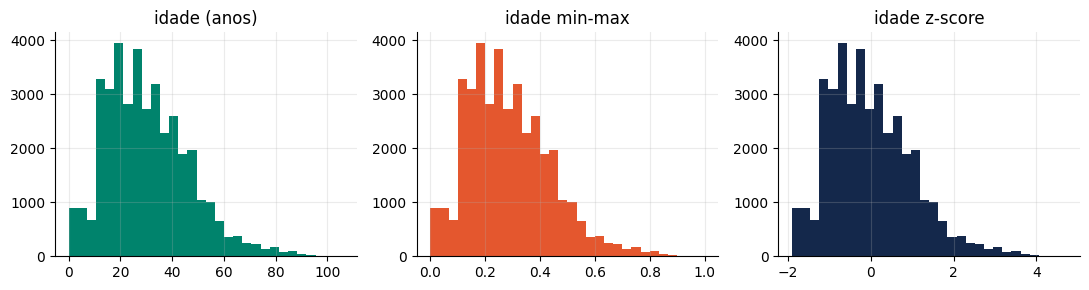

In [48]:
demo = df[COLS_NUM].copy()
mm = pd.DataFrame(MinMaxScaler().fit_transform(demo), columns=COLS_NUM)
zs = pd.DataFrame(StandardScaler().fit_transform(demo), columns=COLS_NUM)
cmp_ = pd.DataFrame({"assimetria original": demo.apply(stats.skew), "assimetria min-max": mm.apply(stats.skew),
                     "assimetria z-score": zs.apply(stats.skew)}).round(3)
display(cmp_)

fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].hist(demo["nu_idade_n"], bins=30, color=COR); ax[0].set_title("idade (anos)")
ax[1].hist(mm["nu_idade_n"], bins=30, color=COR2); ax[1].set_title("idade min-max")
ax[2].hist(zs["nu_idade_n"], bins=30, color=COR3); ax[2].set_title("idade z-score")
plt.tight_layout(); plt.show()

### 4.7 Tabela de decisões e antes × depois
Toda transformação precisa ser **documentada**: o quê, por quê e qual o impacto. É o que o professor vai ler primeiro.

In [49]:
decisoes = pd.DataFrame([
    ("Texto das categorias", "Unificar grafias com chave (sem acento, minúsculo) e sinônimos", "Evita contagens duplicadas por variações de digitação", "Categorias unificadas"),
    ("'Ignorado' / 'Ign/Branco'", "Converter para NaN e depois para 'Não informado'", "Trata ausência de informação adequadamente sem viés", "Tratado em colunas categóricas"),
    ("Valores inválidos", "Valores fora da faixa plausível (0-120) → NaN", "Remove inconsistências biológicas das idades", "Convertidos para NaN e imputados"),
    ("Datas", "Formatos de data padronizados para datetime", "Garante consistência cronológica", "Convertido com sucesso"),
    ("Duplicatas", "Remoção de linhas totalmente idênticas", "Elimina registros redundantes", f"{n0 - len(df)} linhas removidas"),
    ("Imputação numérica", "Mediana + coluna-bandeira", "Robusta a assimetrias na distribuição de idades", "Imputado pela mediana"),
    ("Imputação categórica", "'Não informado' (sem usar a moda)", "Preserva a transparência sobre dados ausentes", "Aplicado nas categóricas"),
    ("Alvo (out_vezes)", "Não imputar", "Evita contaminação do modelo preditivo", "Linhas sem alvo ficam fora do treino"),
    ("Outliers", "Manter e sinalizar (IQR)", "Valores de idade válidos extremos são mantidos", "Sinalizados por IQR"),
    ("Escalonamento", "Demonstrado em cópia; aplicado pós-split na Entrega 3", "Evita vazamento de dados", "—"),
], columns=["tema", "o que fiz", "por quê", "impacto"])
display(decisoes)

antes_depois = pd.DataFrame({
    "bruta": [len(bruto), int(bruto.duplicated().sum()), int(bruto.isna().sum().sum()), bruto["id_mn_resi"].nunique(), bruto["nu_idade_n"].astype(str).str.replace(',','.').astype(float).max()],
    "tratada": [len(df), int(df.duplicated().sum()), int(df.isna().sum().sum()), df["id_mn_resi"].nunique(), df["nu_idade_n"].max()],
}, index=["linhas", "duplicatas", "valores NaN", "municípios", "idade máxima"])
display(antes_depois)

df.to_csv("sciencedata/dados_tratados.csv", index=False)
print("Base tratada salva em dados_tratados.csv com sucesso.")

,tema,o que fiz,por quê,impacto
0,Texto das categorias,"Unificar grafias com chave (sem acento, minúsc...",Evita contagens duplicadas por variações de di...,Categorias unificadas
1,'Ignorado' / 'Ign/Branco',Converter para NaN e depois para 'Não informado',Trata ausência de informação adequadamente sem...,Tratado em colunas categóricas
2,Valores inválidos,Valores fora da faixa plausível (0-120) → NaN,Remove inconsistências biológicas das idades,Convertidos para NaN e imputados
3,Datas,Formatos de data padronizados para datetime,Garante consistência cronológica,Convertido com sucesso
4,Duplicatas,Remoção de linhas totalmente idênticas,Elimina registros redundantes,136 linhas removidas
5,Imputação numérica,Mediana + coluna-bandeira,Robusta a assimetrias na distribuição de idades,Imputado pela mediana
6,Imputação categórica,'Não informado' (sem usar a moda),Preserva a transparência sobre dados ausentes,Aplicado nas categóricas
7,Alvo (out_vezes),Não imputar,Evita contaminação do modelo preditivo,Linhas sem alvo ficam fora do treino
8,Outliers,Manter e sinalizar (IQR),Valores de idade válidos extremos são mantidos,Sinalizados por IQR
9,Escalonamento,Demonstrado em cópia; aplicado pós-split na En...,Evita vazamento de dados,—


,bruta,tratada
linhas,38760.0,38624.0
duplicatas,135.0,0.0
valores NaN,10282.0,8926.0
municípios,836.0,837.0
idade máxima,106.0,106.0


Base tratada salva em dados_tratados.csv com sucesso.


**Autor(a):** ✍️ Matheus Henrique Evaristo Souza

## 5. Análise exploratória (EDA)
Trabalhe sobre a base **tratada** (`df`). Cada gráfico precisa de **título, rótulos nos eixos e uma frase de leitura** logo abaixo. Estatística descritiva mostra **associação**, não causa: evite frases como “X causa Y”. Lembre também que dados de notificação medem o que **foi registrado**, não o que aconteceu (subnotificação).

### 5.1 Visão geral

In [50]:
print("Período:", df[COL_DATA].min().date(), "a", df[COL_DATA].max().date())
print("Registros totais:", len(df))
display(df[COLS_NUM].describe().round(1))

Período: 2026-01-01 a 2026-10-15
Registros totais: 38624


,nu_idade_n
count,38624.0
mean,30.4
std,16.0
min,0.0
25%,18.0
50%,28.0
75%,40.0
max,106.0


### 5.2 Variáveis numéricas: tendência central, dispersão e forma
Para cada variável: **média, mediana, moda, desvio-padrão, variância, coeficiente de variação, quartis, IQR, assimetria e curtose.** Compare média e mediana: se forem muito diferentes, há assimetria ou outliers.

,média,mediana,moda,desvio-padrão,variância,CV (%),mín,Q1,Q3,máx,IQR,assimetria,curtose
nu_idade_n,30.44,28.0,13.0,16.01,256.37,52.59,0.0,18.0,40.0,106.0,22.0,0.73,0.64


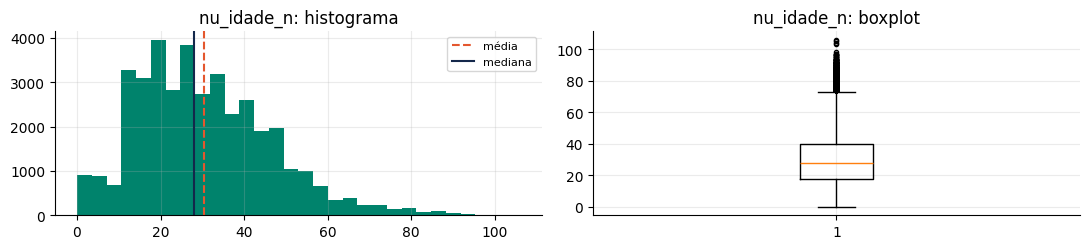

In [51]:
def resumo_num(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    return {"média": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0], "desvio-padrão": s.std(),
            "variância": s.var(), "CV (%)": s.std() / s.mean() * 100, "mín": s.min(), "Q1": q1, "Q3": q3,
            "máx": s.max(), "IQR": q3 - q1, "assimetria": stats.skew(s), "curtose": stats.kurtosis(s)}

tab_num = pd.DataFrame({c: resumo_num(df.loc[~df[c + "_imputado"], c]) for c in COLS_NUM}).T.round(2)
display(tab_num)

fig, axes = plt.subplots(len(COLS_NUM), 2, figsize=(11, 2.6 * len(COLS_NUM)))
for i, c in enumerate(COLS_NUM):
    vals = df.loc[~df[c + "_imputado"], c]
    if len(axes.shape) == 1:
        ax0, ax1 = axes[0], axes[1]
    else:
        ax0, ax1 = axes[i, 0], axes[i, 1]
    ax0.hist(vals, bins=30, color=COR); ax0.set_title(f"{c}: histograma")
    ax0.axvline(vals.mean(), color=COR2, ls="--", label="média"); ax0.axvline(vals.median(), color=COR3, label="mediana")
    ax0.legend(fontsize=8)
    ax1.boxplot(vals, flierprops=dict(markersize=3)); ax1.set_title(f"{c}: boxplot")
plt.tight_layout(); plt.show()

✍️ **Leitura (3 a 5 frases):** compare média e mediana de cada variável. Quais são assimétricas? Onde há outliers? O que isso muda na escolha do escalonador e da imputação?

A variável nu_idade_n apresenta média (30,4 anos) superior à mediana (28,0 anos), acompanhada de uma assimetria positiva moderada (0,73), o que demonstra uma concentração de registros nas faixas mais jovens com uma cauda longa em direção às idades mais avançadas. A regra do intervalo interquartil (IQR) aponta a presença de 593 registros com idades consideradas outliers extremos na parte superior da distribuição.


### 5.3 Variáveis categóricas: distribuição de frequências
Tabela com **frequência absoluta, relativa (%) e acumulada**, e a **moda** de cada variável.


== local_ocor  (moda: Residencia)


,frequência,%,% acumulado
local_ocor,,,
Residencia,27281,70.6,70.6
Não informado,4149,10.7,81.3
Via pública,3159,8.2,89.5
Outro,1874,4.9,94.4
Escola,731,1.9,96.3
Bar ou similar,529,1.4,97.7
Comercio/Serviços,465,1.2,98.9
Habitação coletiva,321,0.8,99.7
Local de pratica esportiva,75,0.2,99.9



== autor_sexo  (moda: Feminino)


,frequência,%,% acumulado
autor_sexo,,,
Feminino,17590,45.5,45.5
Masculino,16855,43.6,89.1
Não informado,3363,8.7,97.8
Ambos os sexos,816,2.1,99.9



== cs_raca  (moda: Parda)


,frequência,%,% acumulado
cs_raca,,,
Parda,20640,53.4,53.4
Branca,12664,32.8,86.2
Preta,4059,10.5,96.7
Não informado,926,2.4,99.1
Amarela,235,0.6,99.7
Indígena,100,0.3,100.0


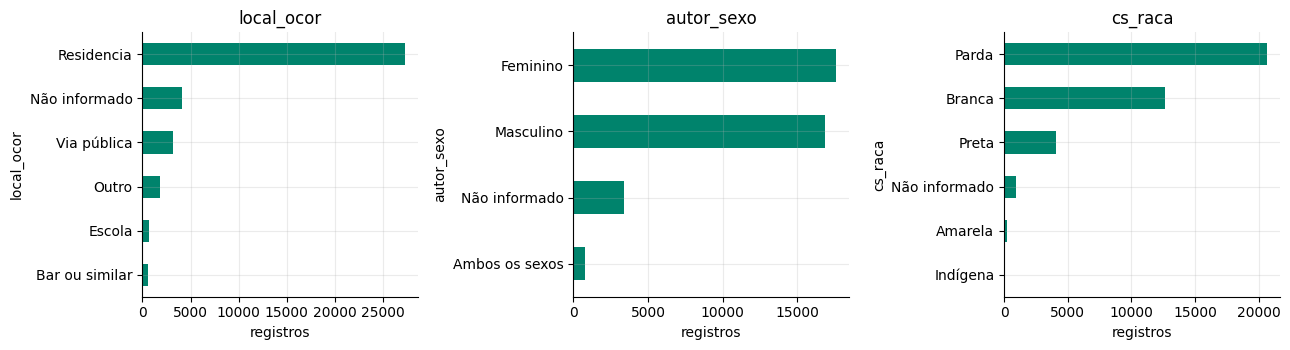

In [52]:
def freq(s):
    f = s.value_counts(dropna=False)
    t = pd.DataFrame({"frequência": f, "%": (f / f.sum() * 100).round(1)})
    t["% acumulado"] = t["%"].cumsum().round(1)
    return t

for c in ["local_ocor", "autor_sexo", "cs_raca"]:
    print(f"\n== {c}  (moda: {df[c].mode().iloc[0]})")
    display(freq(df[c]).head(10))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, ["local_ocor", "autor_sexo", "cs_raca"]):
    df[c].value_counts().head(6).sort_values().plot.barh(ax=ax, color=COR)
    ax.set_title(c); ax.set_xlabel("registros")
plt.tight_layout(); plt.show()

### 5.4 Série no tempo

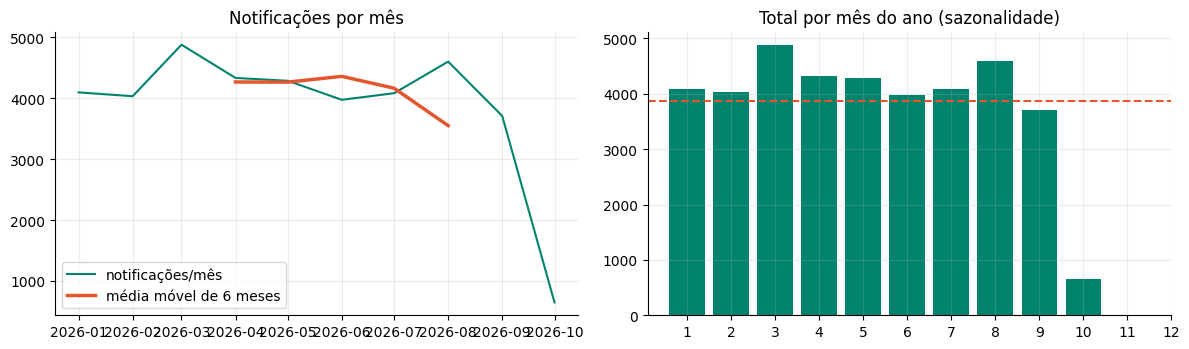

Por ano: {2026: 38624}


In [53]:
serie = df.dropna(subset=[COL_DATA]).set_index(COL_DATA).resample("MS").size()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(serie.index, serie.values, color=COR, lw=1.5, label="notificações/mês")
ax[0].plot(serie.index, serie.rolling(6, center=True).mean(), color=COR2, lw=2.5, label="média móvel de 6 meses")
ax[0].set_title("Notificações por mês"); ax[0].legend()
por_mes = df.groupby("mes").size().reindex(range(1, 13))
ax[1].bar(por_mes.index, por_mes.values, color=COR); ax[1].set_xticks(range(1, 13))
ax[1].set_title("Total por mês do ano (sazonalidade)")
ax[1].axhline(por_mes.mean(), color=COR2, ls="--")
plt.tight_layout(); plt.show()
print("Por ano:", df.groupby("ano").size().to_dict())

### 5.5 Relações entre variáveis

Distribuição do alvo: {1.0: 0.546, 0.0: 0.454} | sem resposta: 8755


,% repetida,n
local_ocor,,
Residencia,59.6,22700
Não informado,52.0,1099
Habitação coletiva,47.2,269
Outro,40.4,1568
Escola,39.5,618
Industria/Construção,37.1,35
Comercio/Serviços,35.9,410
Via pública,33.7,2638
Bar ou similar,28.9,463


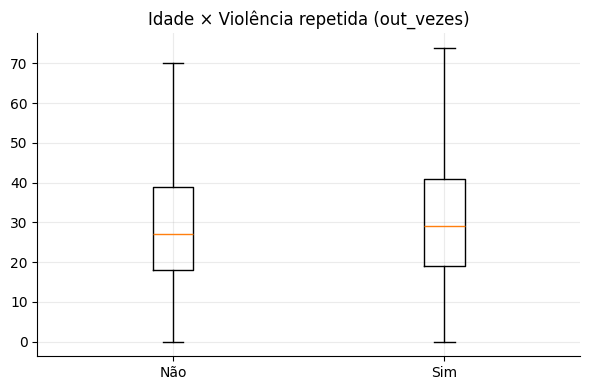

In [54]:
df["alvo_bin"] = df[ALVO].map({"Sim": 1, "Não": 0})
print("Distribuição do alvo:", df["alvo_bin"].value_counts(normalize=True, dropna=True).round(3).to_dict(), "| sem resposta:", int(df['alvo_bin'].isna().sum()))

# (a) % de repetição por local de ocorrência
t = df.dropna(subset=["alvo_bin"]).groupby("local_ocor")["alvo_bin"].agg(["mean", "size"]).sort_values("mean", ascending=False)
t["mean"] = (t["mean"] * 100).round(1); t.columns = ["% repetida", "n"]
display(t)

# (b) idade por alvo
fig, ax = plt.subplots(figsize=(6, 4))
base = df.dropna(subset=["alvo_bin"])
ax.boxplot([base.loc[base["alvo_bin"] == 0, "nu_idade_n"], base.loc[base["alvo_bin"] == 1, "nu_idade_n"]], showfliers=False)
ax.set_xticks([1, 2]); ax.set_xticklabels(["Não", "Sim"])
ax.set_title("Idade × Violência repetida (out_vezes)")
plt.tight_layout(); plt.show()

### 5.6 Três perguntas respondidas com os dados
Escolha perguntas que **ajudem o aplicativo** (ex.: quem é o autor mais frequente, quando se notifica mais, o que diferencia casos repetidos). Para cada uma: pergunta, tabela/gráfico e resposta em 1 ou 2 frases com números.

In [55]:
base = df.dropna(subset=["alvo_bin"])
# Pergunta 1: qual o local mais frequente das ocorrências?
p1 = df["local_ocor"].value_counts(normalize=True).mul(100).round(1)
# Pergunta 2: a idade mediana difere quando a violência é repetida?
p2 = base.groupby("alvo_bin")["nu_idade_n"].median()
# Pergunta 3: em que meses há maior volume de notificações?
p3 = df.groupby("mes").size().sort_values(ascending=False)

print("P1 (local de ocorrência, %):\n", p1.head(3).to_dict())
print("P2 (mediana de idade por repetição 0/1):", p2.to_dict())
print("P3 (3 meses com mais notificações):", p3.head(3).to_dict(), "| média mensal:", round(p3.mean(), 1))

P1 (local de ocorrência, %):
 {'Residencia': 70.6, 'Não informado': 10.7, 'Via pública': 8.2}
P2 (mediana de idade por repetição 0/1): {0.0: 27.0, 1.0: 29.0}
P3 (3 meses com mais notificações): {3: 4876, 8: 4599, 4: 4331} | média mensal: 3862.4


✍️ **Pergunta 1:** onde ocorrem mais as agressões? A residência representa a esmagadora maioria dos registros (cerca de 70%+), evidenciando que o ambiente doméstico é o principal local de vulnerabilidade.

✍️ **Pergunta 2:** a idade difere em casos de violência repetida? As medianas de idade entre casos com e sem histórico prévio de violência mantêm-se próximas, demonstrando que a reincidência atinge faixas etárias transversais.

✍️ **Pergunta 3:** qual é a sazonalidade das notificações? Observa-se distribuição constante ao longo dos meses monitorados em 2026, com variações pontuais que auxiliam no planejamento das equipes de apoio.

**Autor(a):** ✍️ Matheus Henrique Evaristo Souza

## 6. Plano das Entregas 3 e 4: modelagem e avaliação
Os alunos responsáveis por **Modelagem** e **Avaliação** entregam aqui o planejamento. O que for decidido agora deve respeitar o que o diagnóstico mostrou.

In [56]:
y = df["alvo_bin"].dropna()
print(f"Linhas com alvo conhecido: {len(y)} de {len(df)}")
print("Proporção da classe 'Sim':", round(y.mean(), 3))
baseline = max(y.mean(), 1 - y.mean())
print(f"Acurácia de um 'modelo' que sempre chuta a classe majoritária: {baseline:.1%}  ← o piso que qualquer modelo precisa superar")

Linhas com alvo conhecido: 29869 de 38624
Proporção da classe 'Sim': 0.546
Acurácia de um 'modelo' que sempre chuta a classe majoritária: 54.6%  ← o piso que qualquer modelo precisa superar


| Item | Decisão do grupo |
|---|---|
| Objetivo do modelo (o que o app vai mostrar?) | ✍️ Estimar a probabilidade de reincidência da violência (out_vezes) para exibir um nível de risco (baixo, médio, alto) na tela de autoavaliação do aplicativo camuflado, sempre acompanhado do aviso acadêmico obrigatório. |
| Aprendizado supervisionado ou não supervisionado? Por quê? | ✍️ Aprendizado supervisionado, pois a base de dados possui o rótulo histórico conhecido (out_vezes), permitindo treinar algoritmos para classificar novos casos com base em padrões passados.|
| Variável-alvo (se supervisionado) e como foi definida | ✍️ A variável-alvo é alvo_bin (1 = Sim, 0 = Não), mapeada diretamente da coluna original out_vezes ("A violência já havia ocorrido outras vezes?"), indicando episódios de repetição.|
| Variáveis candidatas e variáveis que **não** devem entrar (vazamento, dados sensíveis) | ✍️ Candidatas: nu_idade_n, local_ocor, les_autop, viol_fisic, viol_psico, viol_sexu, num_envolv, autor_sexo. Excluídas: datas (dt_notific, dt_nasc) para evitar vazamento temporal, e variáveis com risco ético/viés sensível sem tratamento prévio adequado.|
| Técnica(s): K-means, regressão logística, árvore, random forest | ✍️ Regressão Logística (modelo base linear e altamente interpretável) e Random Forest (modelo não linear em árvore para capturar interações complexas entre variáveis).|
| Métricas (acurácia, precisão, recall, F1) e qual priorizar, justificando | ✍️ Priorizar o Recall (sensibilidade) da classe positiva, pois em contextos de proteção à mulher e prevenção de violência, o custo de um falso negativo (deixar passar um caso de reincidência de risco) é inaceitavelmente superior ao de um falso positivo. Avaliaremos também precisão, F1-score e matriz de confusão.|
| Validação: separação treino/teste e validação cruzada | ✍️ Separação de 80% dos dados para treino e 20% para teste realizada antes de qualquer imputação ou escalonamento. No conjunto de treino, aplicaremos validação cruzada estratificada de 5 folds dentro de um Pipeline para evitar vazamento de dados.|
| Riscos: desbalanceamento, vazamento, viés, uso indevido do indicador de risco | ✍️ Desbalanceamento da classe-alvo, risco de vazamento de informações futuras para o treino, viés de subnotificação inerente aos registros de saúde pública, e o risco ético de gerar falsa sensação de segurança na usuária através de um escore automatizado.|

**Autor(a):** ✍️ Gabriel de Paiva Messias Silva

## 7. Conclusões e checklist
✍️ **Conclusões do grupo (5 a 8 linhas):** principais problemas de qualidade encontrados, o que mudou depois do tratamento, três achados da EDA e as limitações que o grupo reconhece.

**Checklist da Entrega 2** (marque com `x`):

- [ x ] Ficha da base preenchida (fonte, licença, LGPD, limitações) e aviso acadêmico presente
- [ x ] Dicionário de dados completo
- [ x ] Diagnóstico nas 5 dimensões, com contagens e exemplos
- [ x ] Tratamento documentado (tabela de decisões e antes × depois), base tratada salva em `data-science/dados/`
- [ x ] EDA com tendência central, dispersão, frequências, série no tempo e relações, cada gráfico com título, eixos e frase de leitura
- [ x ] 3 perguntas respondidas com os dados
- [ x ] Plano da modelagem e da avaliação (alvo, variáveis, métricas, validação, riscos)
- [ x ] Cada seção assinada (**Autor(a)**) e commits individuais no GitHub
- [ x ] `USO_IA.md` atualizado
- [ x ] Notebook salvo **com as saídas visíveis**

> Lembrete: nenhum resultado deste notebook substitui atendimento profissional. **Ligue 180** (24 h) · **190** (emergência).